# Emma Scratch Work - EDA

Raw file: `data/raw/jobs-data.csv`

Tasks: 
- checks the raw table
- explore data
- picks the yes/no label
- saves the train, validation, test files with `seed = 1969`

next: add more eda visuals like corr matrix


Summary for teammates: 
- 30,000 rows, 13 columns 
- no NAs or duplicate rows (SYNTHETIC) 
- Job Status matches the openings direction on only about half the rows, so the label is whether 2030 openings are higher than 2024 openings
- predictors: industry, location, education, AI impact, salary, experience, remote ratio, automation risk, gender diversity (dont really separate growing from shrinking jobs)
- dropped: Job title, Job Status, opening columns 

Split currently (can change if want) 
- 70/15/15 train/val/test
- seed = 1969 
- saved files are in data/processed 


In [19]:
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import joblib

# load and peek at data 
raw = pd.read_csv('../data/raw/jobs-data.csv')
print(raw.head())
print(raw.shape)

               Job Title       Industry  Job Status AI Impact Level  \
0     Investment analyst             IT  Increasing        Moderate   
1  Journalist, newspaper  Manufacturing  Increasing        Moderate   
2      Financial planner        Finance  Increasing             Low   
3        Legal secretary     Healthcare  Increasing            High   
4  Aeronautical engineer             IT  Increasing             Low   

   Median Salary (USD) Required Education  Experience Required (Years)  \
0             42109.76    Master’s Degree                            5   
1            132298.57    Master’s Degree                           15   
2            143279.19  Bachelor’s Degree                            4   
3             97576.13   Associate Degree                           15   
4             60956.63    Master’s Degree                           13   

   Job Openings (2024)  Projected Openings (2030)  Remote Work Ratio (%)  \
0                 1515                       6342   

### Inspection 

synthetic - no nulls or duplicates

In [4]:
raw.isna().sum() # synthetic data so no NAs
raw.duplicated().sum() # no duplicates 

raw.describe(include="all")

raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 13 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Job Title                    30000 non-null  str    
 1   Industry                     30000 non-null  str    
 2   Job Status                   30000 non-null  str    
 3   AI Impact Level              30000 non-null  str    
 4   Median Salary (USD)          30000 non-null  float64
 5   Required Education           30000 non-null  str    
 6   Experience Required (Years)  30000 non-null  int64  
 7   Job Openings (2024)          30000 non-null  int64  
 8   Projected Openings (2030)    30000 non-null  int64  
 9   Remote Work Ratio (%)        30000 non-null  float64
 10  Automation Risk (%)          30000 non-null  float64
 11  Location                     30000 non-null  str    
 12  Gender Diversity (%)         30000 non-null  float64
dtypes: float64(4), int64(3), st

### Look at Target

Job Status might not indicated more jobs opening up. 

In [21]:
openings = raw["Projected Openings (2030)"] > raw["Job Openings (2024)"]
status_inc = raw["Job Status"].eq("Increasing")

agreement = (openings == status_inc).mean()
print("Number of rows where Status matches Openings direction: ", agreement)
print(raw["Job Status"].value_counts(normalize=True))

Number of rows where Status matches Openings direction:  0.5025333333333334
Job Status
Increasing    0.504533
Decreasing    0.495467
Name: proportion, dtype: float64


50% rows where status matches openings directions 

Target = openings --> drop `Job Openings (2024)`, `Projected Openings (2030)`, `Job Status`

In [22]:
y = openings.astype(int)

print("openings")
print(y.value_counts(normalize=True))

openings
1    0.501867
0    0.498133
Name: proportion, dtype: float64


### Data Checks 

Summary: job titles dropped bc too many unique values - 639

In [24]:
print(raw.nunique())

for col in ["Industry", "Location", "Required Education", "AI Impact Level", "Job Status"]:
    print("\n", col)
    print(raw[col].value_counts())


Job Title                        639
Industry                           8
Job Status                         2
AI Impact Level                    3
Median Salary (USD)            29968
Required Education                 5
Experience Required (Years)       21
Job Openings (2024)             9439
Projected Openings (2030)       9410
Remote Work Ratio (%)           9466
Automation Risk (%)             9519
Location                           8
Gender Diversity (%)            5965
dtype: int64

 Industry
Industry
Entertainment     3895
Manufacturing     3855
Healthcare        3771
Finance           3721
Education         3714
Retail            3702
IT                3681
Transportation    3661
Name: count, dtype: int64

 Location
Location
Australia    3802
UK           3784
Canada       3775
China        3763
Germany      3741
Brazil       3728
USA          3713
India        3694
Name: count, dtype: int64

 Required Education
Required Education
Bachelor’s Degree    6146
Master’s Degree     

In [25]:
# synthetic data checks
# print(raw.groupby("Required Education")["Median Salary (USD)"].median().sort_values())
# print(raw.groupby("Experience Required (Years)")["Median Salary (USD)"].median())
# print(raw.groupby("AI Impact Level")["Automation Risk (%)"].median())

# industries_per_title = raw.groupby("Job Title")["Industry"].nunique()
# print(industries_per_title.describe())
# print("Share of titles that appear in more than one industry:", (industries_per_title > 1).mean())

Note: salary barely rises with education and experience count 

### Signal / Checking medians and ranges

Shows everything is evenly split.

   Median Salary (USD)  Experience Required (Years)  Remote Work Ratio (%)  \
y                                                                            
0             90049.10                         10.0                 49.455   
1             90608.02                         10.0                 49.690   

   Automation Risk (%)  Gender Diversity (%)  
y                                             
0               49.330                49.795  
1               50.645                50.000  


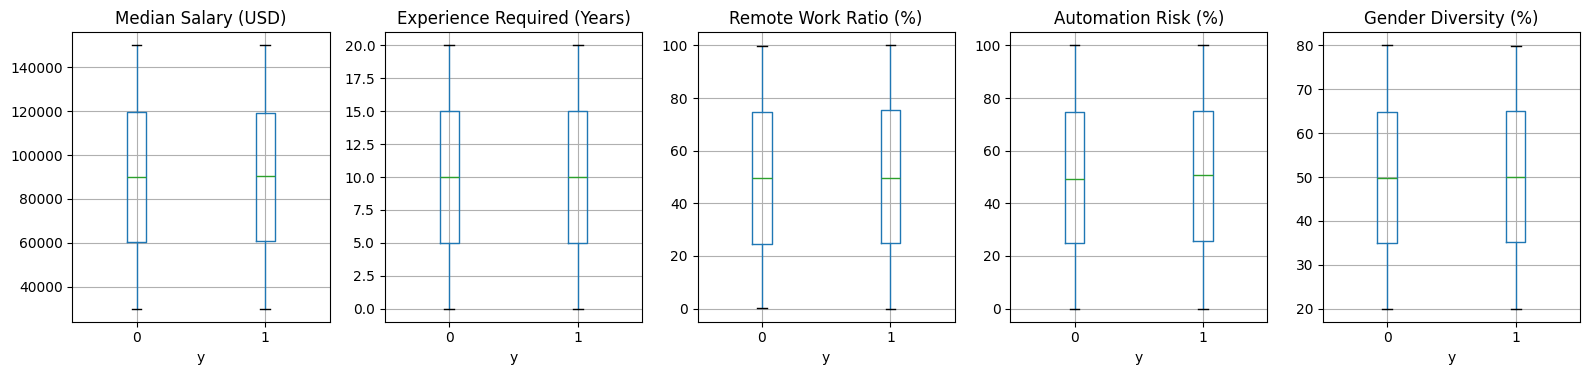


 Industry
Industry
Transportation    0.482109
Education         0.497038
Healthcare        0.500663
Finance           0.502016
Manufacturing     0.502724
Entertainment     0.506547
Retail            0.510265
IT                0.513176
Name: y, dtype: float64

 Location
Location
Canada       0.492185
Germany      0.496659
China        0.499336
India        0.499459
UK           0.502114
Brazil       0.502682
USA          0.508753
Australia    0.513677
Name: y, dtype: float64

 Required Education
Required Education
Bachelor’s Degree    0.488448
Associate Degree     0.495919
Master’s Degree      0.501886
PhD                  0.507004
High School          0.516780
Name: y, dtype: float64

 AI Impact Level
AI Impact Level
Moderate    0.499104
Low         0.500854
High        0.505647
Name: y, dtype: float64


In [26]:
import matplotlib.pyplot as plt

labeled = raw.copy()
labeled["y"] = y

num_cols = [
    "Median Salary (USD)",
    "Experience Required (Years)",
    "Remote Work Ratio (%)",
    "Automation Risk (%)",
    "Gender Diversity (%)",
]
print(labeled.groupby("y")[num_cols].median())

fig, axes = plt.subplots(1, len(num_cols), figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    labeled.boxplot(column=col, by="y", ax=ax)
    ax.set_title(col)

plt.suptitle("")
plt.tight_layout()
plt.show()

for col in ["Industry", "Location", "Required Education", "AI Impact Level"]:
    print("\n", col)
    print(labeled.groupby(col)["y"].mean().sort_values())

### Columns

Target: openings (Job Status matches the openings direction on only about half the rows, so the label is whether 2030 openings are higher than 2024 openings)

Drop: 
- Job Openings (2024) and Projected Openings (2030) (answer)
- Job Status (does not follow openings growth)
- Job Title (639 total and every title shows up in 7/8 industries)

Keep: 
- Industry, Location, Required Education, and AI Impact Level (yes/no columns (one-hot encode))
- salary, experience, remote ratio, automation risk, and gender diversity (standardize for training)

Signal check:
- none of the kept columns really separate growing jobs from shrinking ones
- Medians are almost the same for both classes
- every category sits near a 50% chance of growth

In [27]:
seed = 1969
keep = [
    "Industry",
    "AI Impact Level",
    "Required Education",
    "Location",
    "Median Salary (USD)",
    "Experience Required (Years)",
    "Remote Work Ratio (%)",
    "Automation Risk (%)",
    "Gender Diversity (%)",
]

# drop_cols = [
#    "Job Status",
#    "Job Openings (2024)",
#    "Projected Openings (2030)",
#   "Job Title",]

X = raw[keep].copy()

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=seed, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=seed, stratify=y_temp)

out = Path("../data/processed")
out.mkdir(parents=True, exist_ok=True)

def save_split(features, target, name):
    part = features.copy()
    part["y"] = target.to_numpy()
    part.to_csv(out / f"{name}.csv", index=False)

save_split(X_train, y_train, "train")
save_split(X_val, y_val, "val")
save_split(X_test, y_test, "test")

cat = ["Industry", "AI Impact Level", "Required Education", "Location"]
num = [c for c in keep if c not in cat]
pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat),
                         ("num", StandardScaler(), num)])
pre.fit(X_train)
joblib.dump(pre, out / "preprocessor.joblib")

print(len(X_train), len(X_val), len(X_test))

21000 4500 4500
